In [3]:
import io
import urllib.request
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import powerlaw

**Dataset**: Red de relaciones entre los terroristas que atacaron con bombas la estación de trenes de Madrid el día 11 de Marzo de 2004.

El dataset está obtenido de la página `networks.skewed`, que contiene redes de diferentes tamaños. 

He intentado escoger un dataset **relevante**, **manejable** (pequeño, para las visualizaciones) e **interpretable**.

Más información sobre el dataset en http://konect.cc/networks/moreno_train

---

**Interpretación de la matriz de adyacencia**: Las aristas $(i,j)$ vienen pesadas con un valor positivo de 1 a 4, que indica la intensidad del vínculo (fuerza de interacción en la investigación judicial original de José A. Rodríguez, 2005):

1. Contacto esporádico o enlace débil (reuniones puntuales, llamadas telefónicas).
2. Vínculo de amistad o co-participación frecuente.
3. Enlace operativo estrecho o co-detención previa.
4. Vínculo familiar directo o co-residencia

---

Software específico utilizado: NetworkX https://pypi.org/project/networkx/


In [13]:
# 0. Carga de datos
from sys import path
path = "/home/samuel/Work/Máster UNED/Redes Neuronales y Complejas/moreno_train/out.moreno_train_train"

path = "/home/samuel/Work/Máster UNED/Redes Neuronales y Complejas/moreno_train/out.moreno_train_train"

df = pd.read_csv(path, sep=" ", header=None, names=["i", "j", "weight"], comment="%")
df.head(10)

,i,j,weight
0,1,2,1
1,1,3,3
2,1,4,1
3,1,5,1
4,1,6,1
5,1,7,4
6,1,8,1
7,1,9,1
8,1,10,4
9,1,11,1


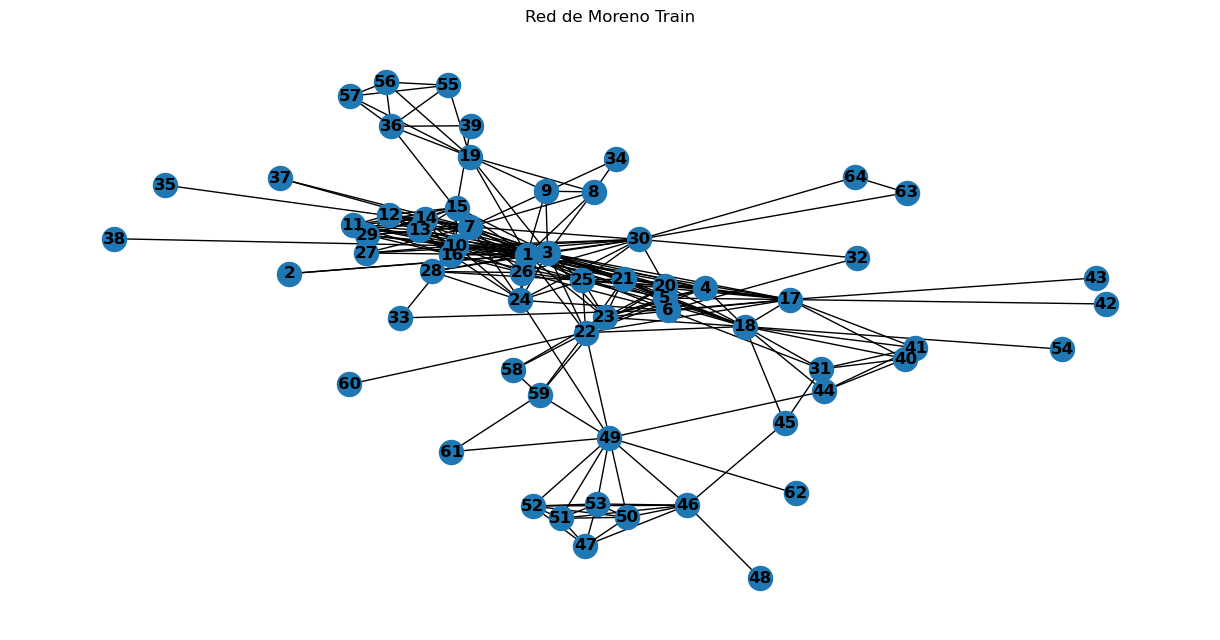

In [25]:
# 1. Representación de la red como un grafo
G = nx.from_pandas_edgelist(df, source="i", target="j", edge_attr="weight", create_using=nx.Graph())

plt.figure(figsize=(12, 6))
nx.draw(G, with_labels=True, font_weight='bold')
plt.title("Red de Moreno Train")
plt.show()

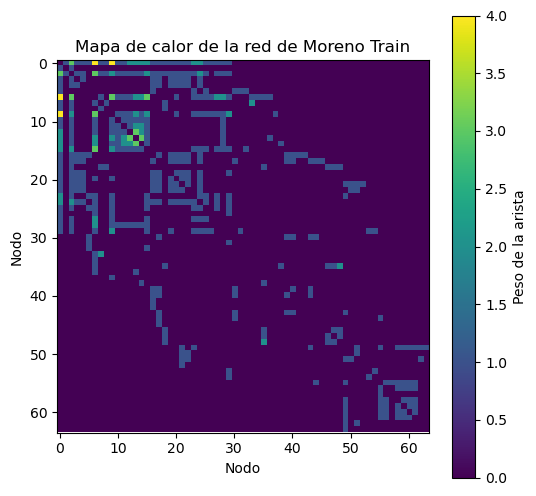

In [37]:
# 1.1 Representación de aristas de la red como mapa de calor
plt.figure(figsize=(6, 6))
# Matriz de adyacencia
adj_matrix = nx.to_numpy_array(G)
plt.imshow(adj_matrix, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Peso de la arista')
plt.title("Mapa de calor de la red de Moreno Train")
plt.xlabel("Nodo")
plt.ylabel("Nodo")
plt.show()

Número de nodos: 64
Número de aristas: 243
Diameter: 6
Grado promedio: 7.59375
Coeficiente de clustering promedio: 0.6223250206309917
Camino medio empírico: 2.691 | Teórico ER: 2.051
Clustering empírico: 0.622 | Teórico ER: 0.119
Top 5 por Grado: [(1, 29), (3, 27), (7, 22), (10, 18), (25, 17)]
Top 5 por Intermediación (cuellos de botella/puentes): [(49, 0.2296569891295954), (1, 0.20089716941995484), (3, 0.16427966506051503), (24, 0.13772902712994878), (7, 0.13705370000812914)]
Valores propios de la matriz de adyacencia: almacenados en la variable eigenvalues
Coeficiente de asortatividad r: 0.0295
La red es asortativa (nodos de alto grado tienden a conectarse con otros de alto grado).


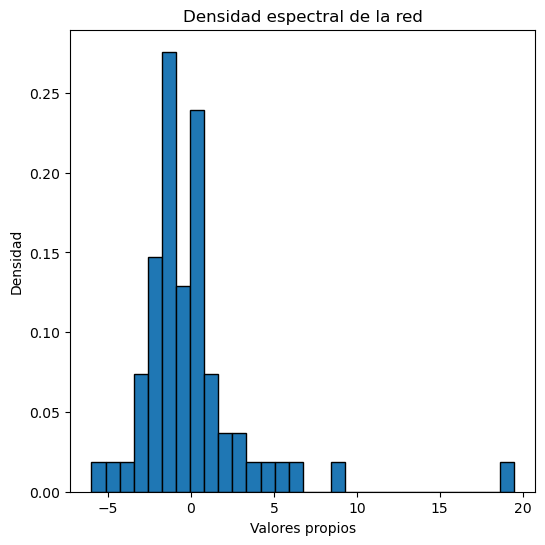

In [43]:
# 2. Propiedades de la red

# Número de nodos y aristas
print(f"Número de nodos: {G.number_of_nodes()}")
print(f"Número de aristas: {G.number_of_edges()}")

# Diameter (camino más largo entre dos nodos)
print(f"Diameter: {nx.diameter(G)}")

# Grado k_i (número de conexiones de cada nodo)
degrees = [G.degree(n) for n in G.nodes()]
print(f"Grado promedio: {np.mean(degrees)}")

# Coeficiente de clustering (medida de la tendencia de los nodos a formar clústeres)
clustering_coeffs = nx.clustering(G)
print(f"Coeficiente de clustering promedio: {np.mean(list(clustering_coeffs.values()))}")

# Longitud de camino promedio (promedio de las distancias más cortas entre todos los pares de nodos)
l_mean = nx.average_shortest_path_length(G)
k_mean = np.mean(degrees)
N = G.number_of_nodes()

C_rand = k_mean / N
l_rand = np.log(N) / np.log(k_mean)

print(f"Camino medio empírico: {l_mean:.3f} | Teórico ER: {l_rand:.3f}")
print(f"Clustering empírico: {np.mean(list(clustering_coeffs.values())):.3f} | Teórico ER: {C_rand:.3f}")

# Centralidades y Jerarquía (Identificación de Nodos Críticos)
betweenness = nx.betweenness_centrality(G)
eigen_cent = nx.eigenvector_centrality(G, max_iter=1000)

# Comparativa de los 5 nodos más críticos
top_degree = sorted(G.degree(), key=lambda x: x[1], reverse=True)[:5]
top_betweenness = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:5]

print("Top 5 por Grado:", top_degree)
print("Top 5 por Intermediación (cuellos de botella/puentes):", top_betweenness)

# Espectro del grafo (valores propios de la matriz de adyacencia)
adj_matrix = nx.adjacency_matrix(G).todense()
eigenvalues = np.linalg.eigvals(adj_matrix)
print(f"Valores propios de la matriz de adyacencia: almacenados en la variable eigenvalues")

# Coeficiente de Asortatividad de Grado (r)
r = nx.degree_assortativity_coefficient(G)
print(f"Coeficiente de asortatividad r: {r:.4f}")
if r > 0:
    print("La red es asortativa (nodos de alto grado tienden a conectarse con otros de alto grado).")
elif r < 0:
    print("La red es disortativa (nodos de alto grado tienden a conectarse con nodos de bajo grado).")

# Densidad espectral (medida de la distribución de los valores propios)
density_spectral = np.histogram(eigenvalues, bins=30, density=True)
# plot de la densidad espectral
plt.figure(figsize=(6, 6))
plt.bar(density_spectral[1][:-1], density_spectral[0], width=np.diff(density_spectral[1]), edgecolor="black", align="edge")
plt.title("Densidad espectral de la red")
plt.xlabel("Valores propios")
plt.ylabel("Densidad")
plt.show()
